In [1]:
from spacegraph_codebase.SpatialRelationEncoder import *
from spacegraph_codebase.utils import *

ffn = get_ffn(128, 128, 0.1)
stg = StochasticGate(3021)
model = WaveletMultisolSpatialRelationEncoder(128, ffn=ffn, stg=stg)

Create 3 FeedForward NN!!!!!!!!!!


AttributeError: 'int' object has no attribute 'use_layn'

In [1]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    x = torch.randn(1000, 1000, device="cuda")
    y = x @ x
    torch.cuda.synchronize()
    print("CUDA calculation: OK")

CUDA available: True
GPU: NVIDIA RTX 4000 SFF Ada Generation
CUDA calculation: OK


In [2]:
inp = torch.rand(64, 128, 2)
ou = model.wlfunc(inp, [0,0], 1, 1)
print(ou.shape)

torch.Size([64, 128, 3])


In [3]:
ou = model.wlfunc.phph(inp, [0,0], 1, 1)
print(ou.shape)

torch.Size([64, 128])


In [4]:
ou = model.make_input_embeds([[[1,1], [2,2]]])

In [5]:
ou.shape

torch.Size([1, 2, 3021])

In [8]:
model2 = TheoryGridCellSpatialRelationEncoder(spa_embed_dim = 128)
inp = np.random.rand(64, 128, 2)
ou = model2.make_input_embeds(inp)
print(ou.shape)

(64, 128, 96)


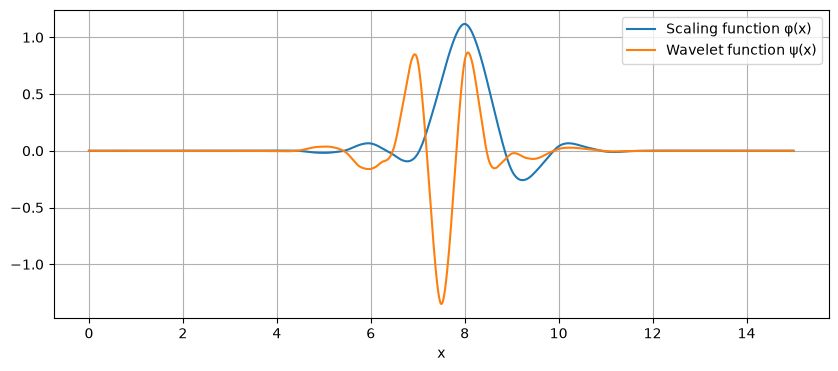

In [8]:
import pywt
import numpy as np
import matplotlib.pyplot as plt

# wavelet = pywt.Wavelet("db8")
wavelet = pywt.Wavelet("sym8")
# wavelet = pywt.Wavelet("coif2")
# wavelet = pywt.Wavelet("haar")

# スケーリング関数 φ、ウェーブレット関数 ψ
phi, psi, x = wavelet.wavefun(level=10)

plt.figure(figsize=(10, 4))

plt.plot(x, phi, label="Scaling function φ(x)")
plt.plot(x, psi, label="Wavelet function ψ(x)")

plt.xlabel("x")
plt.legend()
plt.grid()
plt.show()

In [8]:
x

array([0.00000000e+00, 9.76562500e-04, 1.95312500e-03, ...,
       9.99023438e-01, 1.00000000e+00, 1.00097656e+00], shape=(1026,))

In [12]:
from scipy.interpolate import interp1d

phi_func = interp1d(
    x, phi, bounds_error=False, fill_value=0
)
psi_func = interp1d(
    x, psi, bounds_error=False, fill_value=0
)

# 任意の座標における値
print(phi_func(112.5))
print(psi_func(2.5))

0.0
0.008568986020206518


In [ ]:
# from spacegraph_codebase.wl_utils import WLFuncForMultisol
from wl_utils import WLFuncForMultisol

db8 = WLFuncForMultisol("db8")

In [21]:
db8((5, 6), (0, 0), 1.0, 0)
db8.phph((5, 6), (0, 0), 1.0, 0)

tensor(-0.0012)

In [1]:
from SpatialRelationEncoder import *

model = WaveletMultisolSpatialRelationEncoder(64, 2, None)

ModuleNotFoundError: No module named 'spacegraph_codebase'